In [1]:
import numpy as np
import pandas as pd
from scipy import stats, optimize
import matplotlib.pyplot as plt

In [2]:
data_arrival = pd.read_csv("Data_Arrivals.csv", index_col=0)
print(data_arrival.head())
hours = list(data_arrival.columns)

x = data_arrival.values.flatten()
n=len(x)
print(n)
print(f'mean={x.mean()}')
print(f'var={x.var(ddof=1)}')
print(f'min={x.min()}')
print(f'max={x.max()}')

      1am  2am  3am  4am  5am  6am  7am  8am  9am  10am  ...  3pm  4pm  5pm  \
Day1    0    0    2    1    0    0    0    2    1     4  ...    3    2    1   
Day2    3    2    1    0    0    0    0    0    3     1  ...    3    4    6   
Day3    1    0    2    1    0    1    1    2    3     0  ...    4    5    8   
Day4    1    0    0    1    0    2    0    5    2     2  ...    4    2    3   
Day5    1    2    0    1    1    1    2    1    1     1  ...    8    2   10   

      6pm  7pm  8pm  9pm  10pm  11pm  12am  
Day1    7    4    5    2     3     4     2  
Day2    6    2    2    3     2     3     3  
Day3    7    4    3    1     2     2     4  
Day4    8    4    8    3     3     3     5  
Day5    5    6    2    3     3     4     3  

[5 rows x 24 columns]
2400
mean=2.975416666666667
var=5.9798039113519526
min=0
max=14


In [3]:
# Define the distributions to be fitted (discrete: counts per hour)
distributions = ['poisson', 'nbinom']

def fitdist(sample, dist):
    """Maximum-likelihood fit; returns (frozen scipy distribution, number of parameters)."""
    mu = sample.mean()
    if dist == 'poisson':
        return stats.poisson(mu), 1
    if dist == 'nbinom':                 # mean fixed at the sample mean (MLE); maximise over r. r -> infinity is the Poisson limit, so r is bounded
        nll = lambda lr: -stats.nbinom.logpmf(sample, np.exp(lr), np.exp(lr) / (np.exp(lr) + mu)).sum()
        r = np.exp(optimize.minimize_scalar(nll, bounds=(np.log(0.05), np.log(1e4)), method='bounded').x)
        return stats.nbinom(r, r / (r + mu)), 2

def fit_summary_table(sample, fits):
    rows = []
    for name, (fd, kpar) in fits.items():
        ll = fd.logpmf(sample).sum()
        rows.append(dict(Distribution=name, Parameters=tuple(round(float(p), 4) for p in fd.args), logLik=round(ll, 1),
                         AIC=round(2*kpar - 2*ll, 1), BIC=round(kpar*np.log(len(sample)) - 2*ll, 1)))
    return pd.DataFrame(rows)

def compare_plots(sample, fits, title=''):
    """denscomp, qqcomp, cdfcomp"""
    ks = np.arange(sample.max() + 1); xs = np.sort(sample); p = (np.arange(1, len(xs) + 1) - 0.5) / len(xs)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    ax[0].bar(ks, [(sample == i).mean() for i in ks], alpha=0.5, label='Data')
    for name, (fd, _) in fits.items(): ax[0].plot(ks, fd.pmf(ks), 'o-', ms=3, label=name)
    ax[0].set_title('Histogram and theoretical pmfs'); ax[0].legend()
    for name, (fd, _) in fits.items(): ax[1].plot(fd.ppf(p), xs, '.', label=name)
    ax[1].plot([0, xs.max()], [0, xs.max()], 'k--'); ax[1].set_title('Q-Q plot'); ax[1].set_xlabel('Theoretical quantiles'); ax[1].set_ylabel('Sample quantiles'); ax[1].legend()
    ax[2].step(ks, [(sample <= i).mean() for i in ks], where='post', c='k', label='Data')
    for name, (fd, _) in fits.items(): ax[2].step(ks, fd.cdf(ks), where='post', label=name)
    ax[2].set_title('Empirical and theoretical CDFs'); ax[2].legend()
    fig.suptitle(title); plt.tight_layout(); plt.show()

def gofstat(sample, fd, kpar):
    """Chi-square goodness of fit (cells pooled until expected count >= 5). KS is not valid for discrete data."""
    ks = np.arange(sample.max() + 1); N = len(sample)
    obs = np.array([(sample == i).sum() for i in ks], float)
    exp = N * fd.pmf(ks); exp[-1] += N * fd.sf(ks[-1])
    o, e, co, ce = [], [], 0, 0
    for a, b in zip(obs, exp):
        co += a; ce += b
        if ce >= 5: o.append(co); e.append(ce); co = ce = 0
    if ce > 0: o[-1] += co; e[-1] += ce
    o, e = np.array(o), np.array(e)
    stat = ((o - e)**2 / e).sum(); dof = len(o) - 1 - kpar
    return stat, dof, (stats.chi2.sf(stat, dof) if dof > 0 else np.nan)

def run(sample, title=''):
    fits = {d: fitdist(sample, d) for d in distributions}
    for d, (fd, kpar) in fits.items():
        print(f'Summary for {d} distribution:'); print(fit_summary_table(sample, {d: (fd, kpar)}).to_string(index=False))
    compare_plots(sample, fits, title)
    for d, (fd, kpar) in fits.items():
        stat, dof, p = gofstat(sample, fd, kpar)
        print(f'Goodness of fit for {d}: chi-square = {stat:.2f}, dof = {dof}, p-value = {p:.4f}')
    return fits

Summary for poisson distribution:
Distribution Parameters  logLik     AIC     BIC
     poisson  (2.9754,) -5614.1 11230.1 11235.9
Summary for nbinom distribution:
Distribution       Parameters  logLik     AIC     BIC
      nbinom (2.5218, 0.4587) -5225.8 10455.7 10467.3


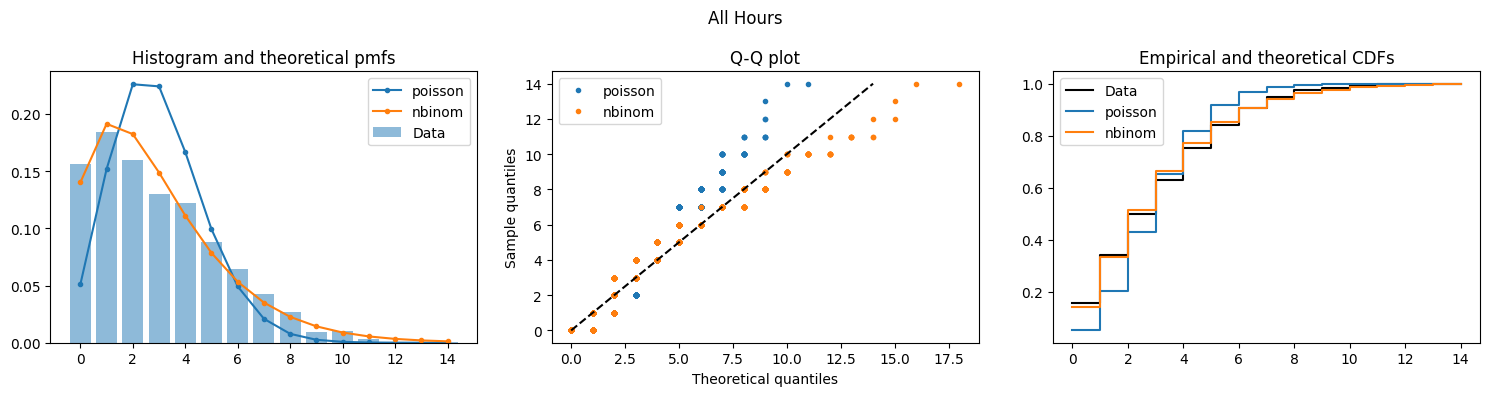

Goodness of fit for poisson: chi-square = 1196.38, dof = 8, p-value = 0.0000
Goodness of fit for nbinom: chi-square = 52.12, dof = 11, p-value = 0.0000
2.975416666666667 5.9798039113519526


In [4]:
fits_all = run(x, "All Hours")
print(x.mean(), x.var(ddof=1))

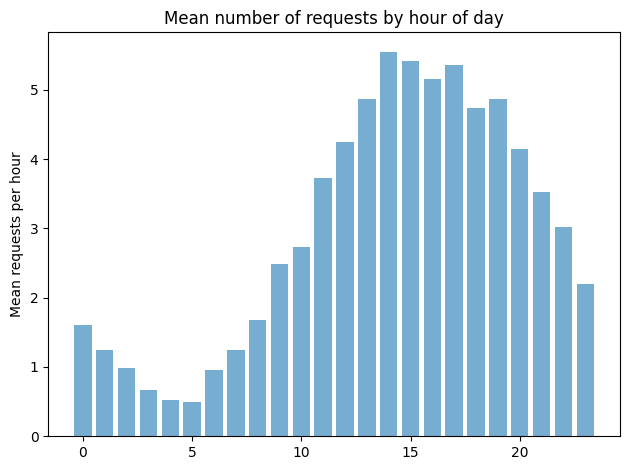

In [15]:
#histogram of the pooled counts with each fit overlaid
plt.bar(range(24), data_arrival.mean(), alpha=0.6)
plt.ylabel('Mean requests per hour')
plt.title('Mean number of requests by hour of day')
plt.tight_layout()
plt.show()

In [16]:
#by the hour
row = []

for hr in hours:
    s =  data_arrival[hr].values
    fits = {d: fitdist(s,d) for d in distributions}
    aic = {d: 2*kp - 2*fd.logpmf(s).sum() for d, (fd, kp) in fits.items()}
    best = min(aic, key=aic.get)
    p_pois = gofstat(s, *fits['poisson'])[2]
    p_nbinom = gofstat(s, *fits['nbinom'])[2]
    row.append(dict(Hour=hr, mean=round(s.mean(), 3), variance=round(s.var(ddof=1), 3), Best_by_AIC=best,
                         AIC_poisson=round(aic['poisson'], 1), AIC_nbinom=round(aic['nbinom'], 1), Poisson_chi2_p=round(p_pois, 4), NegBin_chi2_p=round(p_nbinom, 4)))

by_hour = pd.DataFrame(row)
print(by_hour.to_string(index=False))

print('Hours where Poisson has the lowest AIC:', int((by_hour.Best_by_AIC == 'poisson').sum()), 'of 24')
print('Hours where Poisson is rejected at 5%:', int((by_hour.Poisson_chi2_p < 0.05).sum()), 'of 24')
print('Hours where NegBin is rejected at 5%:', int((by_hour.NegBin_chi2_p < 0.05).sum()), 'of 24')


Hour  mean  variance Best_by_AIC  AIC_poisson  AIC_nbinom  Poisson_chi2_p  NegBin_chi2_p
 1am  1.61     1.250     poisson        303.0       305.0          0.3036         0.1622
 2am  1.25     1.523     poisson        299.0       299.3          0.6840         0.7544
 3am  0.98     0.828     poisson        251.2       253.2          0.1561         0.0539
 4am  0.67     0.607     poisson        214.9       216.9          0.8130            NaN
 5am  0.53     0.696      nbinom        200.7       200.0          0.4982            NaN
 6am  0.49     0.555     poisson        189.0       190.3          0.6595            NaN
 7am  0.95     0.896     poisson        254.3       256.3          0.5000         0.2389
 8am  1.24     1.417     poisson        288.6       290.1          0.3531         0.0711
 9am  1.68     1.371     poisson        310.0       312.0          0.6194         0.4103
10am  2.48     2.232     poisson        357.5       359.5          0.6866         0.5181
11am  2.73     2.967 

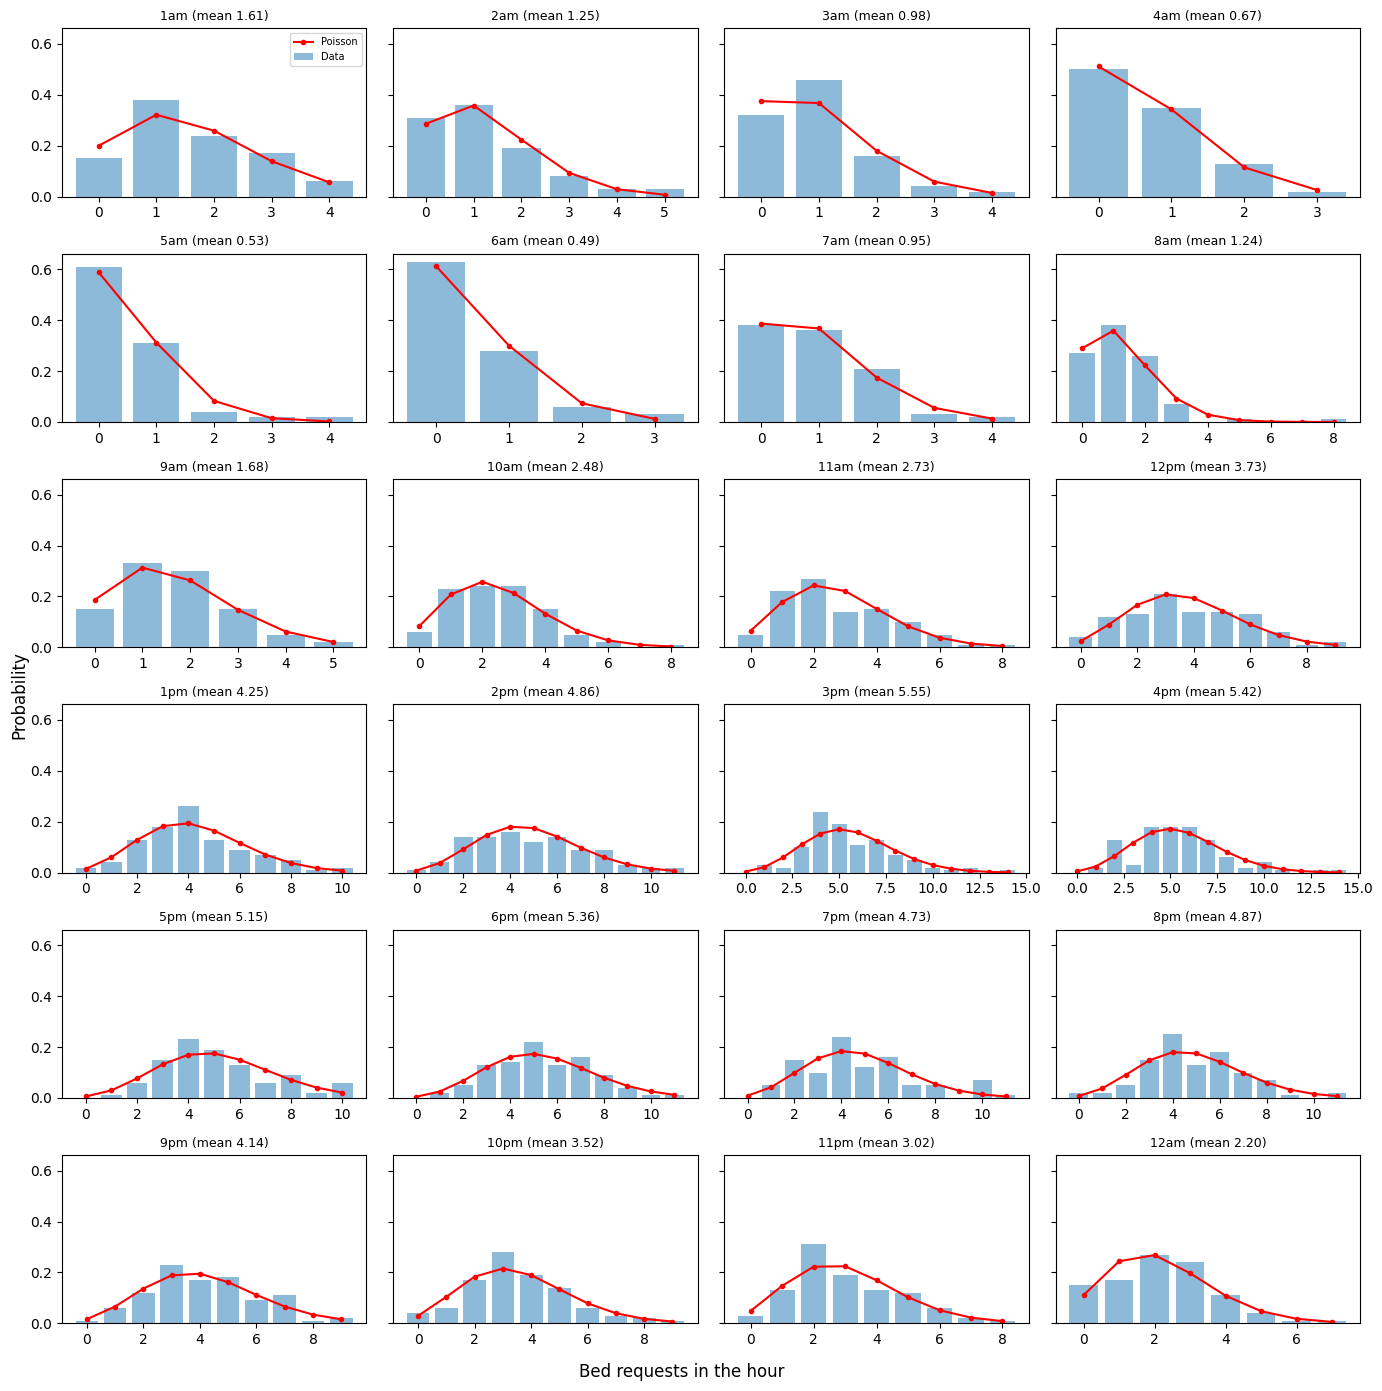

In [ ]:
#the fit distribution if by the hour confirming the appropriate distribution is a non-homogenous Poisson process
fig, axes = plt.subplots(6, 4, figsize=(14, 14), sharey=True)
for ax, hr in zip(axes.ravel(), hours):
    s = data_arrival[hr].values
    fd, _ = fitdist(s, 'poisson')
    k = np.arange(s.max() + 1)
    ax.bar(k, [(s == i).mean() for i in k], alpha=0.5, label='Data')
    ax.plot(k, fd.pmf(k), 'ro-', ms=3, label='Poisson')
    ax.set_title(f'{hr} (mean {s.mean():.2f})', fontsize=9)
axes[0, 0].legend(fontsize=7)
fig.supxlabel('Bed requests in the hour'); fig.supylabel('Probability')
plt.tight_layout(); plt.show()

In [52]:
# independence check (a Poisson process needs independent counts in different hours/days)
M = data_arrival.mean()
adj = [np.corrcoef(data_arrival.iloc[:, j], data_arrival.iloc[:, j+1])[0, 1] for j in range(23)]
print(f'adjacent hours: mean correlation {np.mean(adj):+.3f}, significant pairs {sum(abs(r) > 1.96/np.sqrt(100) for r in adj)} of 23')
seq = ((data_arrival - M) / np.sqrt(M)).values.flatten(); N = len(seq)
acf = [np.corrcoef(seq[:-k], seq[k:])[0, 1] for k in range(1, 25)]
Q = N*(N+2)*sum(acf[k-1]**2/(N-k) for k in range(1, 25)); print(f'Ljung-Box (24 lags): Q={Q:.1f}, p={stats.chi2.sf(Q, 24):.3f}')

# fitted arrival model: lambda(h) = mean count in hour h, with exact 95% CI
S = data_arrival.sum().to_numpy(); lam = data_arrival.mean().to_numpy()
rate_table = pd.DataFrame({'Hour': hours, 'Interval': [f'{h:02d}:00-{h+1:02d}:00' for h in range(24)], 'lambda (per hour)': lam,
                           '95% CI low': stats.chi2.ppf(.025, 2*S)/2/100, '95% CI high': stats.chi2.ppf(.975, 2*(S+1))/2/100}).round(3)
print(rate_table.to_string(index=False)); print('Expected arrivals per day:', lam.sum().round(2))

def generate_arrivals(t_end_hours, rng, lam=lam):
    """Arrival times (hours from midnight) of the fitted process: N~Poisson(lam_h) in each hour, placed uniformly inside the hour."""
    nh = int(np.ceil(t_end_hours)); counts = rng.poisson(np.tile(lam, int(np.ceil(nh/24)))[:nh])
    t = np.concatenate([h + rng.random(c) for h, c in enumerate(counts)]); return np.sort(t[t < t_end_hours])

rng = np.random.default_rng(360); A = generate_arrivals(24*2000, rng)
print('max |simulated hourly mean - lambda| =', np.abs(np.bincount((A % 24).astype(int), minlength=24)/2000 - lam).max().round(3))

adjacent hours: mean correlation -0.024, significant pairs 0 of 23
Ljung-Box (24 lags): Q=25.6, p=0.375
Hour    Interval  lambda (per hour)  95% CI low  95% CI high
 1am 00:00-01:00               1.61       1.371        1.879
 2am 01:00-02:00               1.25       1.040        1.489
 3am 02:00-03:00               0.98       0.796        1.194
 4am 03:00-04:00               0.67       0.519        0.851
 5am 04:00-05:00               0.53       0.397        0.693
 6am 05:00-06:00               0.49       0.363        0.648
 7am 06:00-07:00               0.95       0.769        1.161
 8am 07:00-08:00               1.24       1.031        1.478
 9am 08:00-09:00               1.68       1.436        1.954
10am 09:00-10:00               2.48       2.181        2.809
11am 10:00-11:00               2.73       2.416        3.074
12pm 11:00-12:00               3.73       3.361        4.128
 1pm 12:00-13:00               4.25       3.855        4.674
 2pm 13:00-14:00               4.86       

In [53]:
data = pd.read_csv('Data_TreatmentTimes.csv')
print(data.head())

#surgery = exponential lamda = 0.4237
#Gen Med Lognormal μ = 0.921, σ = 0.949
#Onco Gamma shape = 0.612, scale = 9.689
#Neuro Lognormal μ = 0.53, σ = 1.133

fitted_dists = {
    'Surg': stats.expon(loc=0, scale=1 / 0.4237),
    'Gen Med': stats.lognorm(s=0.949, loc=0, scale=np.exp(0.921)),
    'Onco': stats.gamma(a=0.612, loc=0, scale=9.689),
    'Neuro': stats.lognorm(s=1.133, loc=0, scale=np.exp(0.53)),
}

candidates = {
    'expon': stats.expon,
    'lognorm': stats.lognorm,
    'gamma': stats.gamma,
    #'weibull_min': stats.weibull_min,
}

#fit for these using goodness of fit - use ktest (Kolmogorov-Smirnov test)
t_specialities = ["Ortho", "Renal", "Card" , "Respi", "Gastro-Endo"]
fit_summary = []

time_col = 'Treatment Time (Days)'
speciality = 'Specialty'

def best_fit(sample):
    best = None 
    for name, dist in candidates.items():
        params = dist.fit(sample, floc=0)
        ks_stat, p_val = stats.kstest(sample, dist.cdf, args=params)
        if best is None or ks_stat < best['ks']:
            best = dict(name=name, dist=dist, params=params,
                        ks=ks_stat, p=p_val)
    return best


for spec, grp in data.groupby(speciality):
    #if spec in fitted_dists:
        #continue
    sample = grp[time_col].dropna().to_numpy()
    best = best_fit(sample)
    fitted_dists[spec] = best['dist'](*best['params'])
    fit_summary.append({
        'Specialty': spec,
        'number of samples': len(sample),
        'Best Distribution': best['name'],
        'Parameters (shape(s), loc, scale)': tuple(round(p, 4) for p in best['params']),
        'KS Statistic': round(best['ks'], 4),
        'KS p-value': round(best['p'], 4),
    })

print(pd.DataFrame(fit_summary).to_string(index=False))
print(data.head())
print(data[speciality].unique())

   ID  Treatment Time (Days)    Specialty
0   0               4.640229        Ortho
1   1               0.770322        Renal
2   2               1.911212         Card
3   3               4.199311        Respi
4   4               2.527663  Gastro_Endo
  Specialty  number of samples Best Distribution Parameters (shape(s), loc, scale)  KS Statistic  KS p-value
       Card               4321           lognorm               (0.9862, 0, 1.7772)        0.0103      0.7461
Gastro_Endo               3254             gamma               (0.8467, 0, 3.9863)        0.0067      0.9982
      Ortho               3425             gamma               (1.0147, 0, 5.4112)        0.0089      0.9455
      Renal               3244             gamma               (0.5122, 0, 9.4168)        0.0136      0.5833
      Respi               4321           lognorm               (1.1333, 0, 1.7179)        0.0106      0.7144
   ID  Treatment Time (Days)    Specialty
0   0               4.640229        Ortho
1   1     

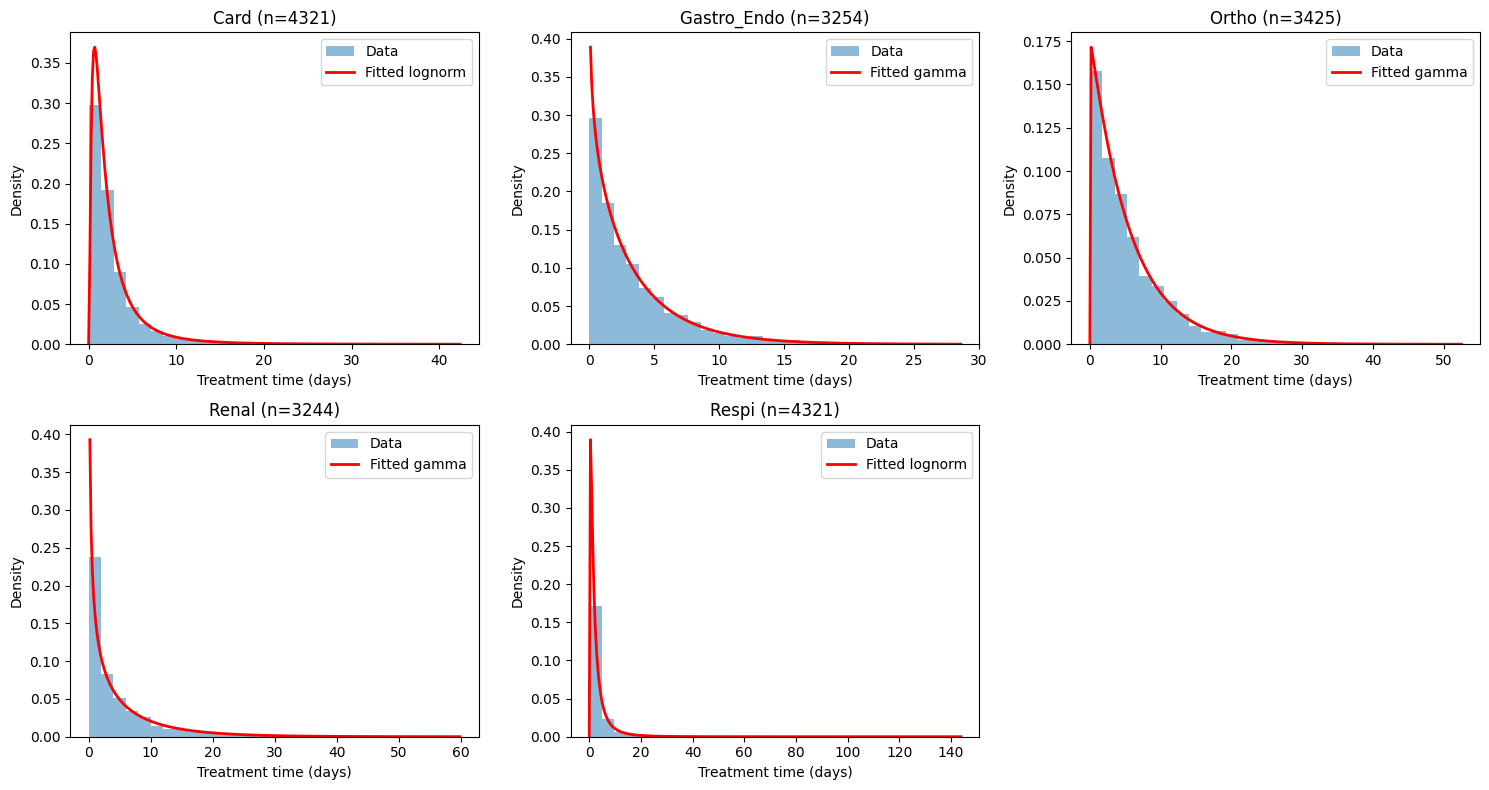

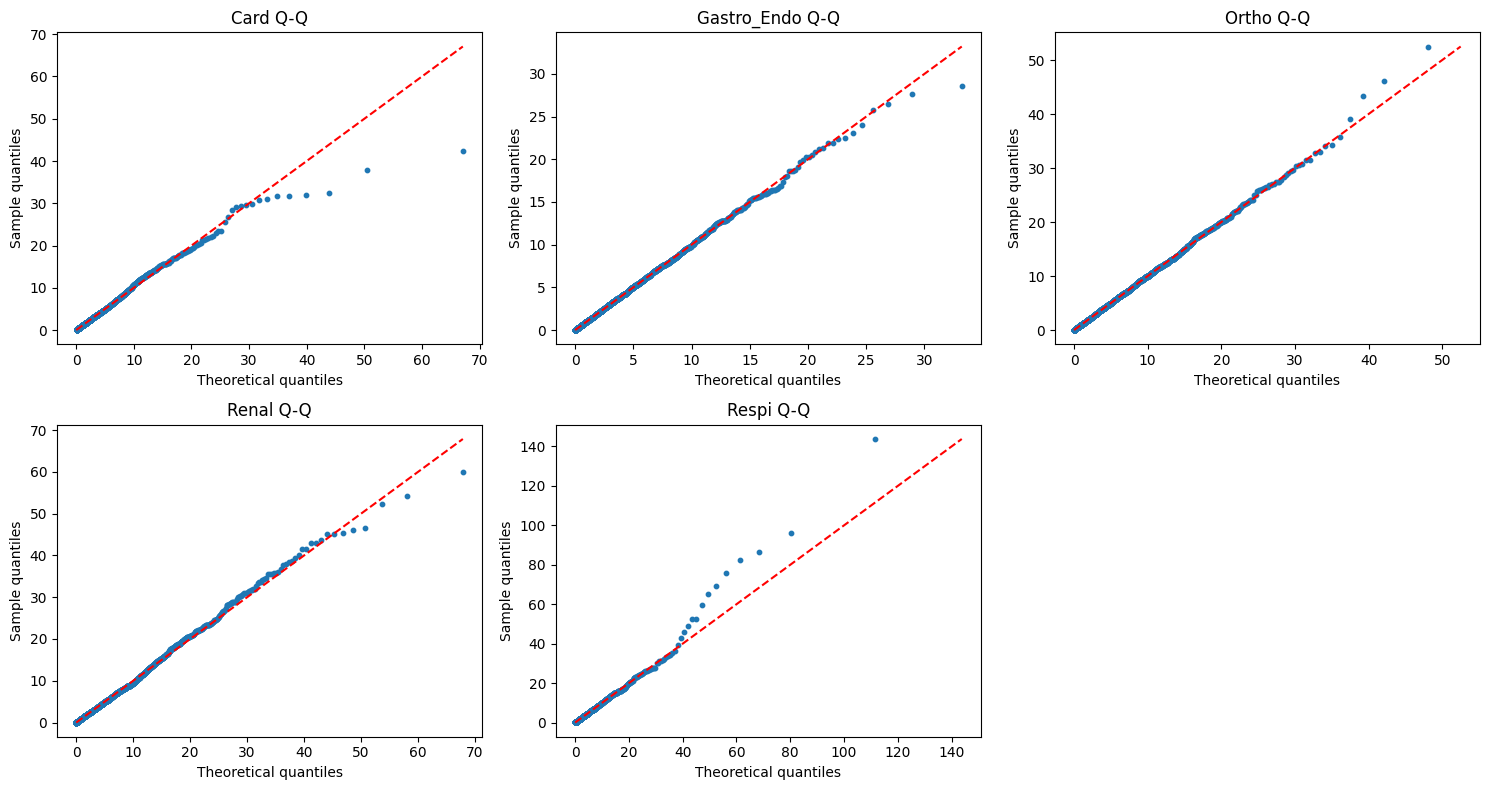

In [54]:
summary_df = pd.DataFrame(fit_summary)
fitted_specs = summary_df['Specialty'].tolist()   # only the GoF-fitted specialties

n = len(fitted_specs)
ncols = 3
nrows = int(np.ceil(n / ncols))

#histogram with fit overlay
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, spec in zip(axes, fitted_specs):
    sample = data.loc[data[speciality] == spec, time_col].dropna().to_numpy()
    dist = fitted_dists[spec]
    best_name = summary_df.loc[summary_df['Specialty'] == spec, 'Best Distribution'].iloc[0]

    x = np.linspace(0, sample.max(), 300)
    ax.hist(sample, bins=30, density=True, alpha=0.5, label='Data')
    ax.plot(x, dist.pdf(x), 'r-', lw=2, label=f'Fitted {best_name}')
    ax.set_title(f'{spec} (n={len(sample)})')
    ax.set_xlabel('Treatment time (days)')
    ax.set_ylabel('Density')
    ax.legend()

for ax in axes[n:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

#qq plots
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = np.atleast_1d(axes).ravel()

for ax, spec in zip(axes, fitted_specs):
    sample = np.sort(data.loc[data[speciality] == spec, time_col].dropna().to_numpy())
    dist = fitted_dists[spec]
    probs = (np.arange(1, len(sample) + 1) - 0.5) / len(sample)
    theo = dist.ppf(probs)

    ax.scatter(theo, sample, s=10)
    lim = [0, max(theo.max(), sample.max())]
    ax.plot(lim, lim, 'r--')
    ax.set_title(f'{spec} Q-Q')
    ax.set_xlabel('Theoretical quantiles')
    ax.set_ylabel('Sample quantiles')

for ax in axes[n:]:
    ax.axis('off')
plt.tight_layout()
plt.show()